# w1 · Tabular models (KKBox churn)

Compare logistic regression, Random Forest and XGBoost using one temporal evaluation:
train and select models on February, evaluate on March, then save the evaluated models.
The main metric is **log-loss**, which measures the quality of predicted probabilities.

## Models

| ID | Model | Input | Search |
|---|---|---|---|
| M1 | Logistic regression | Tabular features | Optuna over regularization strength |
| M2 | Random Forest | Tabular features with ordinal categories | Optuna over forest parameters |
| M3 | XGBoost | Tabular features with native categories | Optuna with early stopping |

## Development and test

| Role | Label month | Features known through | Export file | Use |
|---|---|---|---|---|
| Development | February 2017 | 2017-01-31 | `train_feb.parquet` | `fit`, `stop`, `tune`, then development refit |
| Test | March 2017 | 2017-02-28 | `test.parquet` | Final evaluation |

`test.parquet` contains the labelled March cohort, identified by `TEST_COHORT = "test"`
and `SPLIT["test"]`. Both months have `is_churn` labels.

February is divided into `fit` (75%), `stop` (12.5%) and `tune` (12.5%). Optuna selects
parameters using tune log-loss; XGBoost uses stop for early stopping. Thresholds and the
winning model are selected on tune before any March predictions are made.

The selected parameters are then used to fit each model on all of February. These models
are evaluated on March and saved with the preprocessing needed to reproduce their predictions.

Users can appear in both months with different snapshots and labels. This evaluates the
next month's churn for a recurring subscriber population. Churn prevalence differs between
February (about 6.4%) and March (about 9.0%); the metrics report both rates.

The neural models are in `w2/w2_neural_models.ipynb`.


## 1. Configuration

`run_config` provides the trial budgets, training settings and Random Forest limits.
`run_paths` locates the tabular export and the output directory locally or on Kaggle.

`SMOKE_TEST=True` uses fewer users and trials to check the pipeline quickly, with results
in a separate output directory. `SMOKE_TEST=False` uses the full labelled cohorts.
The smoke setting is a debugging option; March remains the evaluation test in either mode.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd

from src.models.constants import DEV_COHORT, EPS, MODEL_IDS, STUDY_TAGS, TEST_COHORT
from src.models.feature_preparation.config import run_config, run_paths
from src.models.feature_preparation.data import load_cohorts, load_metadata
from src.models.feature_preparation.environment import model_environment
from src.models.feature_preparation.split import (
    make_shared_split, validate_and_save_split,
)
from src.models.feature_preparation.tabular_prep import (
    PhasePreprocessor, make_phase_rows,
)
from src.models.baselines.logistic_regression import run_logistic
from src.models.baselines.random_forest import run_random_forest
from src.models.baselines.random_forest_data import RandomForestData
from src.models.baselines.xgboost_model import run_xgboost
from src.models.evaluation.artifacts import (
    save_models, save_preprocessing, save_run_metadata,
)
from src.models.evaluation.selection import select_on_tune
from src.models.evaluation.refit import (
    fit_development_models, score_test,
)
from src.models.evaluation.tables import (
    DISPLAY_COLUMNS, build_test_tables, save_test_tables,
)
from src.models.evaluation.confusion import save_confusion_figures
from src.models.evaluation.reports import save_classification_reports
from src.models.evaluation.curves import (
    plot_reliability_histogram, plot_roc_pr,
)
from src.models.evaluation.optuna_history import plot_optuna_histories
from src.models.tunning.registry import Registry, SplitData
from src.models.tunning.tunning import (
    contract_hash, get_study as get_persistent_study,
    make_contract, run_study as run_persistent_study,
)

warnings.filterwarnings("ignore")
SMOKE_TEST = False
config = run_config(SMOKE_TEST)
SEED = config["seed"]
OPTUNA_MAX_TRIALS = config["optuna_max_trials"]
TRIALS = config["trials"]
TRAIN_VERBOSE = config["train_verbose"]
TREE_LOG_PERIOD = config["tree_log_period"]
XGB_BALANCED_WEIGHT = config["xgb_balanced_weight"]
TREE_MAX_ROUNDS = config["tree_max_rounds"]
TREE_EARLY_STOP = config["tree_early_stop"]
SMOKE_USERS = config["smoke_users"]
RF_N_ESTIMATORS_MAX = config["rf_n_estimators_max"]
RF_MAX_DEPTH_CAP = config["rf_max_depth_cap"]
RF_MIN_SAMPLES_LEAF_MIN = config["rf_min_samples_leaf_min"]
RF_MIN_SAMPLES_SPLIT_MIN = config["rf_min_samples_split_min"]
print("SMOKE_TEST:", SMOKE_TEST, "| trials:", TRIALS,
      "| total trials:", sum(TRIALS.values()), "| tree rounds:", TREE_MAX_ROUNDS)


SMOKE_TEST: False | trials: {'M1': 3, 'M2': 3, 'M3': 8} | total trials: 14 | tree rounds: 3000


In [2]:
ON_KAGGLE, INPUT_DIR, OUT_DIR = run_paths(SMOKE_TEST)
print("INPUT_DIR:", INPUT_DIR, "| OUT_DIR:", OUT_DIR, "| ON_KAGGLE:", ON_KAGGLE)


INPUT_DIR: export-tabular-v5 | OUT_DIR: artifacts/sherlock_w1 | ON_KAGGLE: False


## 2. Data loading

`load_metadata` checks dataset version 5, the January 31 and February 28 feature cutoffs,
and the feature catalogue. `load_cohorts` reads the two labelled exports and verifies
each file's user order against its metadata hash.

| File | Labels | Role |
|---|---|---|
| `train_feb.parquet` | February churn | Development |
| `test.parquet` | March churn | Test |

The files are stacked into `cohort_df`, with February rows first and March rows second.
`COHORT` identifies each row's source cohort, and every split stores positions in this
shared frame. The exported cohorts are named `train_feb` and `test`.

```mermaid
flowchart LR
    meta["metadata.json"] --> load["load_cohorts"]
    feb["train_feb.parquet · February development"] --> load
    mar["test.parquet · March test"] --> load
    load --> frame["cohort_df · labelled February + March rows"]
```


In [3]:
META, FEATURES, CATEGORICAL, NUMERIC = load_metadata(INPUT_DIR)
print("dataset_version:", META["dataset_version"],
      "| features:", len(FEATURES), "| categorical:", CATEGORICAL)
print("cutoffs:", META["cutoffs"], "| label months:", META["label_months"])


dataset_version: 5 | features: 108 | categorical: ['city', 'registered_via', 'last_payment_method_id']
cutoffs: {'train_feb': '2017-01-31', 'test': '2017-02-28'} | label months: {'train_feb': '2017-02', 'test': '2017-03'}


In [4]:
cohort_df, y_all, COHORT = load_cohorts(
    INPUT_DIR, META, FEATURES, DEV_COHORT, TEST_COHORT
)


train_feb rows:   992,931 | label month: 2017-02 | churn rate: 0.0639
test      rows:   970,960 | label month: 2017-03 | churn rate: 0.0899
labelled cohorts: (1963891, 112) | users in both labelled months: 881701


## 3. Shared split

Every model uses the same `fit`, `stop`, `tune` and `test` rows. A stable user hash assigns
February rows to the development parts, stratified by label. The March cohort supplies
the test rows. The optional smoke run takes a smaller sample from each part.

`make_shared_split` returns `SPLIT` and all February development rows (`DEV_ROWS`).
`validate_and_save_split` checks that parts are disjoint, sorted and contain both classes,
then writes `split_indices.npz` and `split_summary.csv`.

```mermaid
flowchart TD
    feb["February development"] --> hash["stable user hash · stratified by label"]
    hash --> fit["fit · 75%"]
    hash --> stop["stop · 12.5%"]
    hash --> tune["tune · 12.5%"]
    mar["March test"] --> test["test · complete cohort"]
```

The summary records user counts, churn prevalence and `days_to_expire` percentiles.
These diagnostics help inspect the temporal shift between February and March.


In [5]:
SPLIT, DEV_ROWS = make_shared_split(
    cohort_df, COHORT, y_all, smoke_users=SMOKE_USERS, seed=SEED,
    dev_cohort=DEV_COHORT, test_cohort=TEST_COHORT,
)


In [6]:
split_summary, FIT_RATE = validate_and_save_split(
    SPLIT, DEV_ROWS, cohort_df, COHORT, y_all, META, OUT_DIR,
    dev_cohort=DEV_COHORT, test_cohort=TEST_COHORT,
)
split_summary


saved split_indices.npz and split_summary.csv | fit churn rate: 0.06392


,part,cohort,label_month,n_users,churn_rate,n_churn,n_stay,days_to_expire_p01,days_to_expire_p50,days_to_expire_p99
0,fit,train_feb,2017-02,744699,0.06392,47604,697095,NaN,NaN,NaN
1,stop,train_feb,2017-02,124117,0.06392,7934,116183,NaN,NaN,NaN
2,tune,train_feb,2017-02,124115,0.06392,7933,116182,NaN,NaN,NaN
3,test,test,2017-03,970960,0.08994,87330,883630,NaN,NaN,NaN


In [7]:
# Feature subset experiment: train M1/M2/M3 with only these 7 columns.
# Set USE_SUBSET = False to go back to the full feature set.
# It goes after the split: cohort_df keeps every column (the split summary needs
# days_to_expire) and the models only ever read cohort_df[FEATURES].
USE_SUBSET = True
SUBSET = [
    "average_amount_paid",
    "average_amount_charged",
    "is_auto_renew_change_flag",
    "bd_missing",
    "n_payment_methods",
    "last_payment_method_id",
    "registered_via",
]
if USE_SUBSET:
    missing = [c for c in SUBSET if c not in FEATURES]
    assert not missing, f"not in the export: {missing}"
    FEATURES = SUBSET
    CATEGORICAL = [c for c in CATEGORICAL if c in SUBSET]
    NUMERIC = [c for c in FEATURES if c not in CATEGORICAL]
    # Own output folder: fresh Optuna studies (the contract does not hash the feature list)
    # and the sherlock_w1/ models are not overwritten. The same split is saved there too.
    OUT_DIR = OUT_DIR.parent / f"{OUT_DIR.name}_subset7"
    OUT_DIR.mkdir(parents=True, exist_ok=True)
    split_summary, FIT_RATE = validate_and_save_split(
        SPLIT, DEV_ROWS, cohort_df, COHORT, y_all, META, OUT_DIR,
        dev_cohort=DEV_COHORT, test_cohort=TEST_COHORT,
    )
print("features:", len(FEATURES), "| categorical:", CATEGORICAL, "| OUT_DIR:", OUT_DIR)

saved split_indices.npz and split_summary.csv | fit churn rate: 0.06392
features: 7 | categorical: ['registered_via', 'last_payment_method_id'] | OUT_DIR: artifacts/sherlock_w1_subset7


## 4. Preprocessing phases

`make_phase_rows` defines two sets of rows from February: `fit` for tuning and
`development` for the refit on the full month. March supplies no fitted statistics
or category vocabulary.

`PhasePreprocessor` provides a cached numeric and one-hot transformation through
`state(phase)` and `batch(rows, phase)`. The three baselines use their own input preparation:

| Model | Numeric features | Categorical features |
|---|---|---|
| M1 | Median imputation and standard scaling inside its fitted pipeline | One-hot encoding; unseen levels are ignored |
| M2 | Exported numeric features | Ordinal codes from the phase vocabulary; unseen levels become -1 |
| M3 | Exported numeric features | Native categories from the phase vocabulary; unseen levels become missing |

RF and XGBoost learn their category vocabularies from the named February phase.
M1 learns its preprocessing when the pipeline is fitted.


In [8]:
PHASE_ROWS = make_phase_rows(SPLIT, DEV_ROWS)
preprocessor = PhasePreprocessor(
    cohort_df, PHASE_ROWS, FEATURES, CATEGORICAL
)


## 5. Environment (environment.py)

`model_environment(SEED)` seeds the RNGs, silences Optuna's per-trial logging and detects the
XGBoost device from its CUDA build before training. It also returns the library versions stored
with the run artifacts.


In [9]:
XGB_DEVICE, ENV = model_environment(SEED)
print("Environment:", json.dumps(ENV, indent=2))
if XGB_DEVICE == "cpu":
    print("NOTE: XGBoost running on CPU (no CUDA build).")


Environment: {
  "numpy": "2.5.3",
  "pandas": "3.0.6",
  "sklearn": "1.9.1",
  "xgboost": "3.4.1",
  "optuna": "5.0.0",
  "xgb_device": "cuda"
}


## 6. Registry and Optuna studies

`Registry` stores each model's fitted estimator, parameters, trial counts and timings.
It receives tune predictions during model selection and March test predictions after
the development refit. `SplitData` provides row positions and labels for each part.

`make_contract` fingerprints the two labelled cohorts, split sizes, library versions
and model settings. `get_study` creates or resumes the matching persistent Optuna study.
`run_study` runs the remaining trial budget and saves trial CSVs and best-parameter JSONs.

Each baseline keeps its constants, data preparation, model definition, search space,
registration and `run` entry point in that order. RF trains the recorded parameters
exactly and uses the `rf_bounded_v2` study tag.


In [10]:
# Shared model records, probabilities, and row access.
registry = Registry(EPS)
split_data = SplitData(SPLIT, y_all)
REGISTRY = registry.records
PROBA = registry.proba
register = registry.register
set_proba = registry.set_proba
rows_of = split_data.rows
y_of = split_data.y


In [11]:
# Persistent Optuna studies share one data/split contract.
OPTUNA_DIR = OUT_DIR / "optuna"
OPTUNA_DIR.mkdir(parents=True, exist_ok=True)
STORAGE = f"sqlite:///{(OPTUNA_DIR / 'studies.sqlite3').as_posix()}"
CONTRACT = make_contract(
    META, SPLIT, SMOKE_TEST, ENV,
    extra={
        "rf_n_estimators_max": RF_N_ESTIMATORS_MAX,
        "rf_max_depth_cap": RF_MAX_DEPTH_CAP,
        "xgb_balanced_weight": XGB_BALANCED_WEIGHT,
    },
)
CONTRACT_HASH = contract_hash(CONTRACT)


def get_study(model_id):
    return get_persistent_study(
        model_id, CONTRACT, STORAGE, SEED, TRIALS[model_id],
        tag=STUDY_TAGS.get(model_id, ""),
    )


def run_study(model_id, objective, total_trials, enqueue=None):
    return run_persistent_study(
        model_id, objective, get_study(model_id), total_trials,
        OPTUNA_DIR, enqueue=enqueue,
    )


## 7. Tabular studies (M1, M2, M3)

Each model has its own Optuna study. Candidates train on `fit` and are scored by log-loss
on `tune`. XGBoost additionally uses `stop` for early stopping. This section produces
only tune predictions.

M1 uses a `newton-cholesky` logistic pipeline. M2 uses ordinal categorical codes and a
bounded forest search. M3 uses native categorical features and records its best iteration.
The search ranges are defined in each model's `suggest_*_params` function.


In [12]:
# Development labels for all three model families.
y_fit, y_stop, y_tune = y_of("fit"), y_of("stop"), y_of("tune")


In [13]:
# M1: tune and fit logistic regression on the shared split.
run_logistic(
    cohort_df=cohort_df,
    features=FEATURES,
    numeric=NUMERIC,
    categorical=CATEGORICAL,
    split_data=split_data,
    registry=registry,
    study=get_study("M1"),
    total_trials=TRIALS["M1"],
    out_dir=OPTUNA_DIR,
    seed=SEED,
    verbose=TRAIN_VERBOSE,
    eps=EPS,
)


M1: budget=3, remaining=3


  0%|          | 0/3 [00:00<?, ?it/s]

M1: starting trial #0
Newton iter=1
  Check Convergence
    1. max |gradient| 0.09136184038704497 <= 0.0001 False
Newton iter=2
  Check Convergence
    1. max |gradient| 0.0253515974814798 <= 0.0001 False
Newton iter=3
  Check Convergence
    1. max |gradient| 0.00531049640117099 <= 0.0001 False
Newton iter=4
  Check Convergence
    1. max |gradient| 0.000509322315091331 <= 0.0001 False
Newton iter=5
  Check Convergence
    1. max |gradient| 1.4476822169148112e-05 <= 0.0001 True
    2. Newton decrement 1.5873557513678597e-05 <= 0.0001 True
  Solver did converge at loss = 0.19059267623685833.
M1: trial #0 COMPLETE | log-loss=0.1904777194136784 | 3.7s
M1: starting trial #1
Newton iter=1
  Check Convergence
    1. max |gradient| 0.0913646191672091 <= 0.0001 False
Newton iter=2
  Check Convergence
    1. max |gradient| 0.025355925026193916 <= 0.0001 False
Newton iter=3
  Check Convergence
    1. max |gradient| 0.0053153976018241005 <= 0.0001 False
Newton iter=4
  Check Convergence
    1. m

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int32](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['average_amount_paid','average_amount_charged', 'is_auto_renew_change_flag',...,'n_payment_methods', 'last_payment_method_id','registered_via']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

In [14]:
# XGBoost category levels are learned only from the named February phase.
_tree_vocab = {}


def tree_vocab(phase):
    if phase not in _tree_vocab:
        rows = PHASE_ROWS[phase]
        _tree_vocab[phase] = {
            column: sorted(int(v) for v in pd.unique(cohort_df[column].iloc[rows].dropna()))
            for column in CATEGORICAL
        }
    return _tree_vocab[phase]


def tree_frame(rows, phase):
    frame = cohort_df.iloc[np.asarray(rows)][FEATURES].copy()
    # pyarrow reads dictionary-encoded parquet columns as pd.CategoricalDtype.
    # XGBoost 3.x rejects Categorical columns with float categories regardless
    # of enable_categorical — flatten all of them to their underlying numeric dtype.
    cat_cols = frame.select_dtypes(include="category").columns
    for col in cat_cols:
        frame[col] = np.asarray(frame[col])
    # Ordinal-encode the known categorical features against the phase vocabulary.
    vocab = tree_vocab(phase)
    for column in CATEGORICAL:
        codes = {level: idx for idx, level in enumerate(vocab[column])}
        frame[column] = frame[column].map(codes).fillna(-1).astype("int64")
    return frame

In [15]:
# M2: RandomForest keeps a training-only vocabulary for each phase.
rf_data = RandomForestData(
    cohort_df, PHASE_ROWS, FEATURES, CATEGORICAL
)
run_random_forest(
    data=rf_data,
    split_data=split_data,
    registry=registry,
    study=get_study("M2"),
    total_trials=TRIALS["M2"],
    out_dir=OPTUNA_DIR,
    seed=SEED,
    eps=EPS,
)


M2: budget=3, remaining=3


  0%|          | 0/3 [00:00<?, ?it/s]

M2: starting trial #0
M2: trial #0 COMPLETE | log-loss=0.1824731691586049 | 36.2s
M2: starting trial #1
M2: trial #1 COMPLETE | log-loss=0.1828893272725631 | 31.3s
M2: starting trial #2
M2: trial #2 COMPLETE | log-loss=0.18323650390485455 | 20.4s
M2: best tune log-loss=0.18247 | trials {'complete': 3, 'pruned': 0, 'failed': 0}
M2 best params: {'n_estimators': 150, 'max_depth': 12, 'min_samples_leaf': 5, 'min_samples_split': 10, 'max_features': 'sqrt'}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",150
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",12
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",10
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",110
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

In [16]:
# M3: XGBoost uses the shared phase-aware tree_frame.
run_xgboost(
    tree_frame=tree_frame,
    split_data=split_data,
    registry=registry,
    study=get_study("M3"),
    total_trials=TRIALS["M3"],
    out_dir=OPTUNA_DIR,
    device=XGB_DEVICE,
    max_rounds=TREE_MAX_ROUNDS,
    early_stop=TREE_EARLY_STOP,
    log_period=TREE_LOG_PERIOD,
    seed=SEED,
    balanced=XGB_BALANCED_WEIGHT,
    eps=EPS,
)


M3: budget=8, remaining=8


  0%|          | 0/8 [00:00<?, ?it/s]

M3: starting trial #0
[0]	validation_0-aucpr:0.33825


sh: línea 1: nvidia-smi: orden no encontrada


[100]	validation_0-aucpr:0.34820
[200]	validation_0-aucpr:0.35947
[300]	validation_0-aucpr:0.36230
[400]	validation_0-aucpr:0.36393
[500]	validation_0-aucpr:0.36482
[600]	validation_0-aucpr:0.36571
[700]	validation_0-aucpr:0.36575
[760]	validation_0-aucpr:0.36550
M3: trial #0 COMPLETE | log-loss=0.725796639919281 | 4.6s
M3: starting trial #1
[0]	validation_0-aucpr:0.34405
[100]	validation_0-aucpr:0.35408
[200]	validation_0-aucpr:0.35724
[300]	validation_0-aucpr:0.35880
[400]	validation_0-aucpr:0.36034
[500]	validation_0-aucpr:0.36149
[600]	validation_0-aucpr:0.36283
[700]	validation_0-aucpr:0.36387
[800]	validation_0-aucpr:0.36472
[900]	validation_0-aucpr:0.36544
[1000]	validation_0-aucpr:0.36548
[1048]	validation_0-aucpr:0.36546
M3: trial #1 COMPLETE | log-loss=0.7264598608016968 | 8.3s
M3: starting trial #2
[0]	validation_0-aucpr:0.22235
[100]	validation_0-aucpr:0.31430
[200]	validation_0-aucpr:0.32246
[300]	validation_0-aucpr:0.32843
[400]	validation_0-aucpr:0.33152
[500]	validation

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.9759187072563904
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",'cuda'
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",100
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'aucpr'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 8. Tune selection, development refit and test evaluation

`select_on_tune` chooses each model's threshold by churn F1 and the winning model by
log-loss on February tune rows. It writes `selection_manifest.json` before test scoring.

`fit_development_models` refits the selected configurations on all February rows.
`score_test` then evaluates those models on the labelled March cohort using February
preprocessing and the thresholds already selected on tune.

The models saved at the end are these development models evaluated on March.


In [17]:
# Freeze thresholds and winner using February tune predictions only.
THRESHOLDS, SELECTION, primary_winner = select_on_tune(
    y_tune, registry, CONTRACT_HASH, OUT_DIR
)


primary winner (tune): M2
thresholds: {'M1': 0.184, 'M2': 0.212, 'M3': 0.883}


In [18]:
# Refit on February, then evaluate once on the March test.
DEV_MODELS = fit_development_models(
    cohort_df=cohort_df,
    features=FEATURES,
    numeric=NUMERIC,
    categorical=CATEGORICAL,
    dev_rows=DEV_ROWS,
    split_data=split_data,
    registry=registry,
    tree_frame=tree_frame,
    rf_data=rf_data,
    seed=SEED,
    train_verbose=TRAIN_VERBOSE,
    xgb_device=XGB_DEVICE,
    xgb_balanced_weight=XGB_BALANCED_WEIGHT,
)
y_test, TEST_PROBA = score_test(
    models=DEV_MODELS,
    cohort_df=cohort_df,
    features=FEATURES,
    split_data=split_data,
    registry=registry,
    tree_frame=tree_frame,
    rf_data=rf_data,
    selection_manifest=OUT_DIR / "selection_manifest.json",
)


Newton iter=1
  Check Convergence
    1. max |gradient| 0.09137927487516405 <= 0.0001 False
Newton iter=2
  Check Convergence
    1. max |gradient| 0.025366424489469082 <= 0.0001 False
Newton iter=3
  Check Convergence
    1. max |gradient| 0.005326621024378871 <= 0.0001 False
Newton iter=4
  Check Convergence
    1. max |gradient| 0.0005177736335364135 <= 0.0001 False
Newton iter=5
  Check Convergence
    1. max |gradient| 1.6288784056042033e-05 <= 0.0001 True
    2. Newton decrement 1.7981678415535083e-05 <= 0.0001 True
  Solver did converge at loss = 0.19044888298824425.
test probabilities ready for all tabular models


## 9. Test metrics, confusion matrices and curves

`build_test_tables` computes March test metrics at each model's tune threshold and at 0.5.
`save_test_tables` writes `metrics/test_metrics.csv` and `metrics/test_metrics_at_05.csv`.
Classification reports, confusion matrices, ROC/PR curves and reliability plots describe
the same March predictions. Optuna histories describe the February tuning studies.

The displayed table is sorted by test log-loss for inspection. The selected winner
remains the model chosen earlier using tune log-loss.


In [19]:
# Metrics and per-model classification reports.
test_metrics, test_metrics_at_05 = build_test_tables(
    y_tune, y_test, registry, THRESHOLDS, SELECTION
)
save_test_tables(test_metrics, test_metrics_at_05, OUT_DIR)
REPORT_DIR = save_classification_reports(y_test, registry, THRESHOLDS, OUT_DIR)
FIG_DIR = OUT_DIR / "figures"
print("Test = March cohort; tune = February. Prevalence tune/test:",
      round(float(y_tune.mean()), 4), "/", round(float(y_test.mean()), 4))
print("Test metrics ordered by log-loss (winner fixed on tune:",
      primary_winner, ")")
test_metrics[DISPLAY_COLUMNS].round(5)


Test = March cohort; tune = February. Prevalence tune/test: 0.0639 / 0.0899
Test metrics ordered by log-loss (winner fixed on tune: M2 )


,model_id,family,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,M1,logistic,0.19047,0.24300,0.78165,0.43492,0.06598,0.89190,0.72623,0.41926,0.52423,0.92823,0.46591,0.70288,0.40974,0.18355
1,M2,randomforest,0.18247,0.24852,0.78604,0.37853,0.06903,0.86879,0.71702,0.34935,0.53197,0.90208,0.42174,0.67387,0.36120,0.21151
2,M3,xgboost,0.71322,0.81852,0.77815,0.33553,0.27352,0.86919,0.71606,0.34986,0.52934,0.90278,0.42128,0.67377,0.36056,0.88259


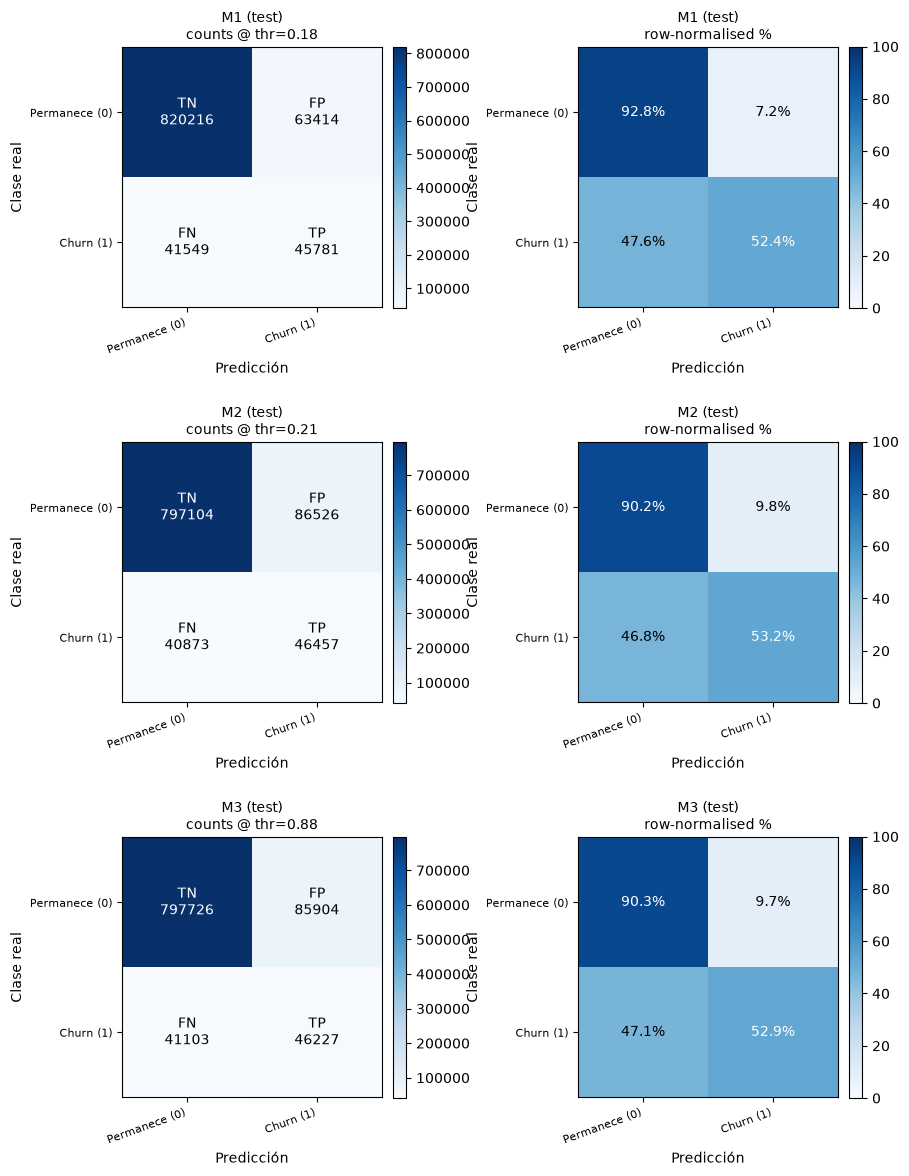

saved per-model confusion images (PNG+SVG) and gallery pages


PosixPath('artifacts/sherlock_w1_subset7/figures/confusion')

In [20]:
save_confusion_figures(y_test, registry, THRESHOLDS, OUT_DIR)


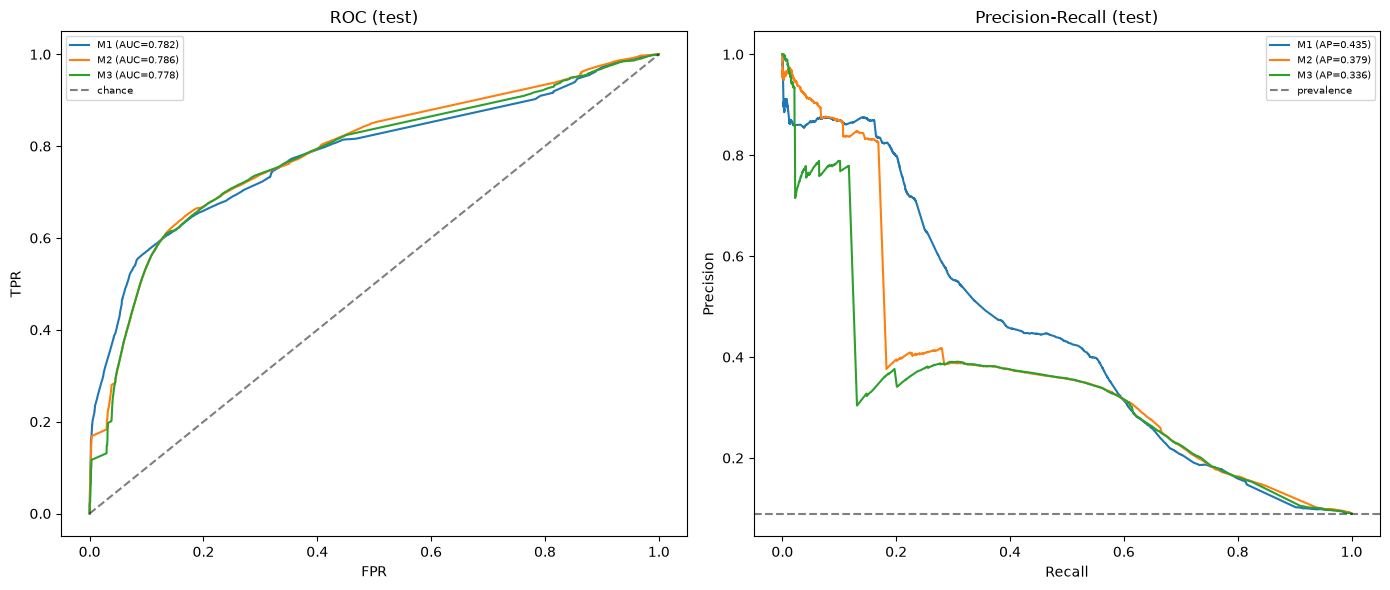

PosixPath('artifacts/sherlock_w1_subset7/figures/curves/roc_pr.png')

In [21]:
plot_roc_pr(y_test, registry, OUT_DIR)


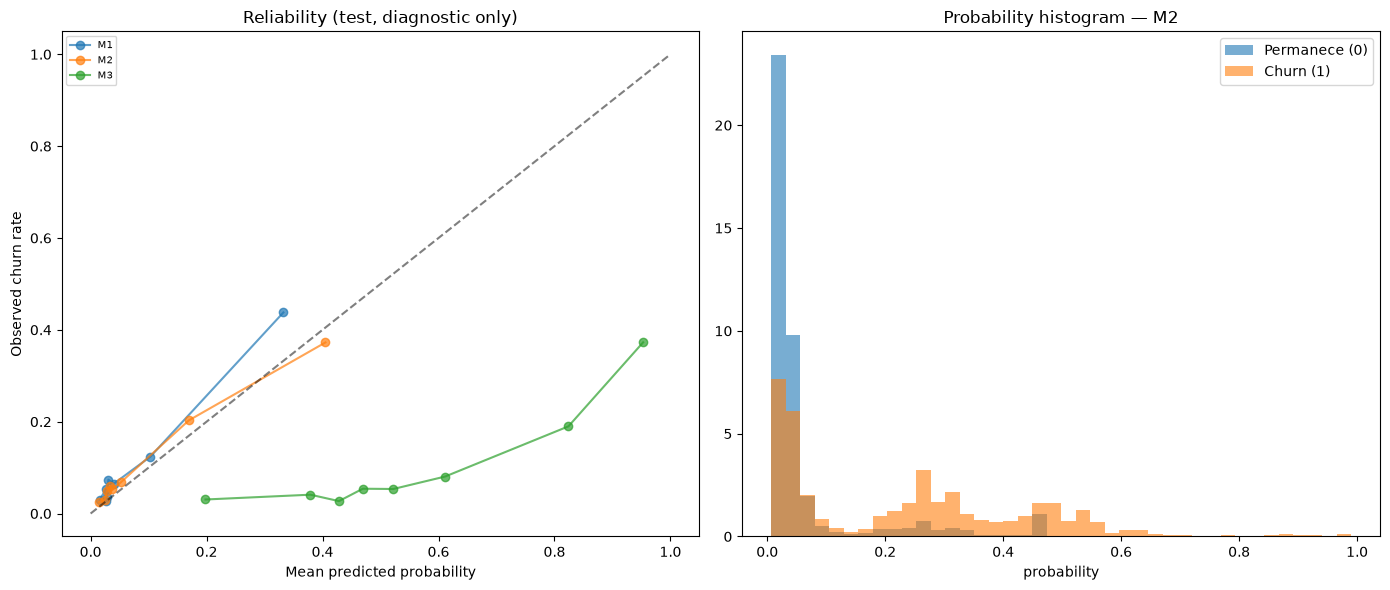

NOTE: reliability curves are diagnostics; no calibration was applied.


PosixPath('artifacts/sherlock_w1_subset7/figures/curves/calibration_hist.png')

In [22]:
plot_reliability_histogram(y_test, registry, primary_winner, OUT_DIR)


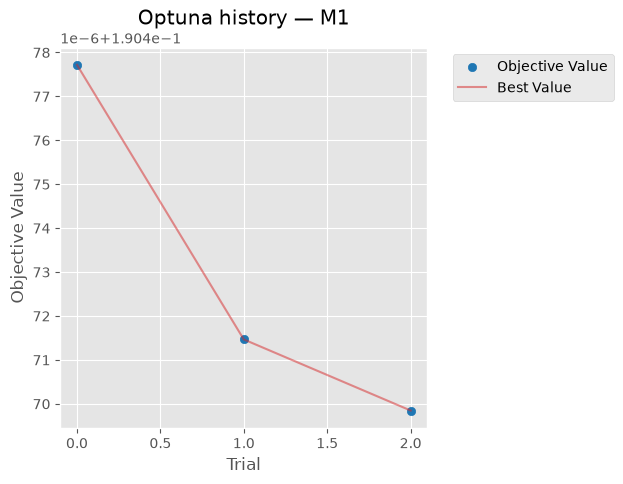

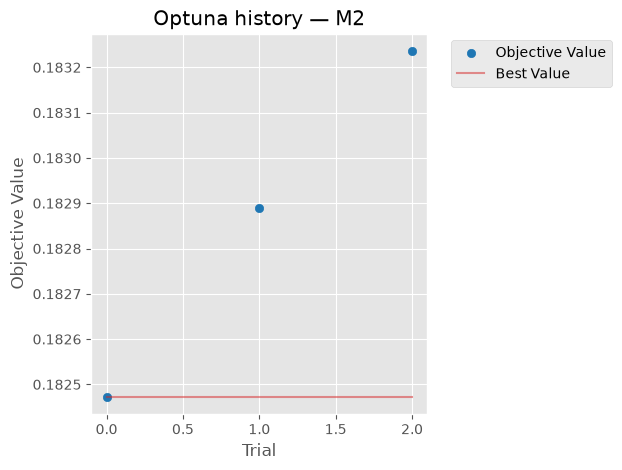

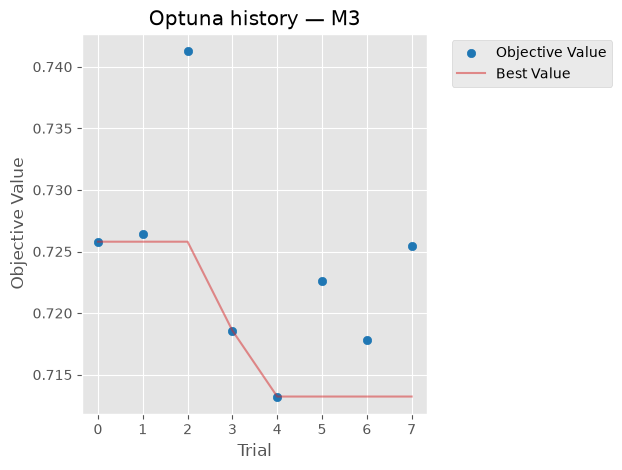

In [23]:
plot_optuna_histories(get_study)


## 10. Save models and artifacts

Save the fitted February models that were evaluated on March. `save_models` writes one
joblib file per model. M1 includes its fitted preprocessing pipeline.
`save_preprocessing` records the feature order, categorical columns, RF/XGBoost development
vocabularies and source preprocessing parameters.

`save_run_metadata` records the run settings, library versions, data contract, selected
winner, exact thresholds and relative artifact paths.

```text
OUT_DIR/
  models/development/
    M1.joblib
    M2.joblib
    M3.joblib
  preprocessing/development.json
  run_config.json
  selection_manifest.json
  split_indices.npz
  split_summary.csv
  metrics/
    test_metrics.csv
    test_metrics_at_05.csv
    classification_reports/
  figures/
  optuna/
```

The preceding sections save the evaluation outputs and studies; the final cell saves
the models and preprocessing. Executing it completes the artifact export.


In [24]:
model_files = save_models(DEV_MODELS, OUT_DIR)
preprocessing_file = save_preprocessing(
    FEATURES,
    CATEGORICAL,
    rf_data.vocab("development"),
    tree_vocab("development"),
    META["preprocess_params"],
    OUT_DIR,
)
run_metadata_path = save_run_metadata(
    config=config,
    env=ENV,
    contract=CONTRACT,
    selection=SELECTION,
    thresholds=THRESHOLDS,
    model_files=model_files,
    preprocessing_file=preprocessing_file,
    out_dir=OUT_DIR,
)
print("Models and artifacts saved in:", OUT_DIR.resolve())
print("Run metadata:", run_metadata_path)


Models and artifacts saved in: /home/alejandropenagos/Escritorio/Alejandro/Machine Learning/customer-churn-prediction/workshops/w1/artifacts/sherlock_w1_subset7
Run metadata: artifacts/sherlock_w1_subset7/run_config.json
